# Notebook to help generate diagrams

In [13]:
import sys
sys.path.append('../scripts')

from peak_tester import EmissionsPeakTest
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from helper_functions import HiddenPrints

In [2]:
# Additional figure: slope distribution with observed slope marked
def plot_slope_distribution(peak_test, ax=None, signif_level=0.1):
    """
    Plot the bootstrap slope distribution with the observed slope marked.

    Args:
        peak_test: fitted EmissionsPeakTest instance (after run_complete_bootstrap_test)
        ax: optional matplotlib Axes; creates a new figure if None
        signif_level: threshold below which slopes are shaded as significant tail
    """
    results = peak_test.bootstrap_results
    slopes = results["bootstrap_slopes"]/1000
    obs_slope = results["test_slope"]/1000
    p_value = results["p_value_one_tail"]
    unit = 'Gt CO2/yr' # if /1000 use Gt, otherwise #peak_test.unit

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4))

    # Histogram of bootstrap slopes
    counts, bin_edges, patches = ax.hist(
        slopes, bins=60, density=True,
        color="#9FE1CB", edgecolor="#5DCAA5", linewidth=0.4,
        label="Bootstrap slopes (H₀: flat trend)"
    )

    # Shade the tail at or below the observed slope
    cutoff = obs_slope
    for patch, left in zip(patches, bin_edges[:-1]):
        if left <= cutoff:
            patch.set_facecolor("#1D9E75")
            patch.set_edgecolor("#0F6E56")

    # Observed slope line
    ax.axvline(
        obs_slope, color="#D85A30", linewidth=1.8, linestyle="--",
        label=f"Observed slope ({obs_slope:.1f} {unit})"
    )

    # ax.axvspan(slopes.min(), obs_slope, alpha=0.15, color="#1D9E75", zorder=0)
    
    ax.set_xlim(-2, 2)
    # p-value annotation
    ax.text(
        0.04, 0.96,
        f"p = {p_value:.2f}",
        transform=ax.transAxes,
        va="top", ha="left", fontsize=10,
        color="#D85A30"
    )

    ax.set_xlabel(f"Slope ({unit}/yr)")
    ax.set_ylabel("Density")
    ax.legend(fontsize=9, framealpha=0.5)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3, linewidth=0.5)

    return ax

In [3]:
def plot_sequential_distributions(peak_test, figsize=None):
    """
    Plot per-step simulation distributions for the sequential method.
    One panel per test year, showing the null distribution and observed value.
    """
    results = peak_test.bootstrap_results  # Convert to Gt if stored in Mt
    sims_dict = results["simulated_values_dict"]  # Get the stored simulations for each step
    p_steps = results["p_sequential_steps"]
    obs = peak_test.test_data["emissions"]
    unit = 'Gt CO2/yr' #peak_test.unit

    years = list(sims_dict.keys())
    n = len(years)
    figsize = figsize or (4 * n, 4)
    fig, axes = plt.subplots(1, n, figsize=figsize, sharey=False)
    if n == 1:
        axes = [axes]

    for ax, year in zip(axes, years):
        sims = sims_dict[year] / 1000  # Convert to Gt if stored in Mt
        obs_val = obs.loc[year] / 1000  # Convert to Gt if stored in Mt
        p_val = p_steps.loc[year]

        counts, bin_edges, patches = ax.hist(
            sims, bins=50, density=True,
            color="#9FE1CB", edgecolor="#5DCAA5", linewidth=0.4,
        )
        for patch, left in zip(patches, bin_edges[:-1]):
            if left <= obs_val:
                patch.set_facecolor("#1D9E75")
                patch.set_edgecolor("#0F6E56")

        ax.axvline(obs_val, color="#D85A30", linewidth=1.8, linestyle="--")
        ax.text(0.05, 0.96, f"p = {p_val:.2f}", transform=ax.transAxes,
                va="top", ha="left", fontsize=10, color="#D85A30")

        ax.set_title(str(year), fontsize=11)
        ax.set_xlabel(f"{unit}")
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.3, linewidth=0.5)
        ax.set_xlim(np.percentile(sims, 0.5),np.percentile(sims, 99.5))

    axes[0].set_ylabel("Density")
    fig.suptitle("Sequential null distributions vs observed", fontsize=12, y=1.02)
    plt.tight_layout()
    return axes

In [4]:
emissions_tester = EmissionsPeakTest()
emissions_tester.load_historical_data(
    'gcb_hist_co2.csv', region='WLD', year_range = range(1970,2025))

Loaded historical data: 1970-2024
Data points: 55


In [5]:
# test a 1% reduction per year
emissions_tester.set_test_data(
        pd.Series(
            index=range(2025,2028),
            data=[emissions_tester.historical_data.iloc[-1].squeeze() * (0.99**n) for n in range(3)])
        )

Test data set: 2025-2027
Test slope: -384.06 Mt CO2 (R² = 1.000)


In [6]:
emissions_tester.characterize_noise(method='broken_trend',include_test_data=True, forced_breakpoints=[2025]) # choose 'normal', 't-dist' or 'empirical'. If 't-dist' can choose t_df or leave to calculate
emissions_tester.create_noise_generator()
emissions_tester.run_complete_bootstrap_test(null_hypothesis='zero_trend',bootstrap_method='ar_bootstrap')


Max breakpoints: 12
using t-dist distribution to calculate noise
Fitted t-distribution to innovations: df = 3.9
Autocorrelation analysis:

  Lag-1 autocorr: 0.426
  Residual σ (post-autocorrelation): 445.9
  Has significant autocorr: True
  Likelihood of autocorr: 0.999125339994859
Noise characterization complete:
  Method used: broken_trend
Using AR(1) noise generator with φ=0.43, mean=-0.000, sigma=445.914
Running complete bootstrap test...
  Null hypothesis: zero_trend
  Bootstrap method: ar_bootstrap
  Bootstrap samples: 10000
using slope-based test method
  P-value slope method: 0.1466
  Significant at α=0.1: False
  Effect size: 0.91 standard deviations


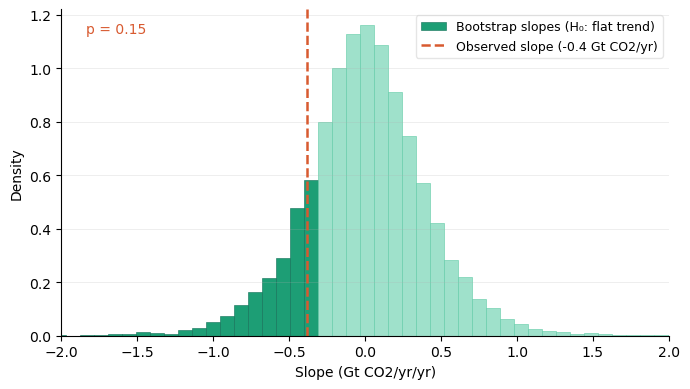

In [30]:

plot_slope_distribution(emissions_tester)
plt.tight_layout()

plt.savefig('../outputs/figures/slope_distribution_1pct_reduction.svg', dpi=300)
plt.show()


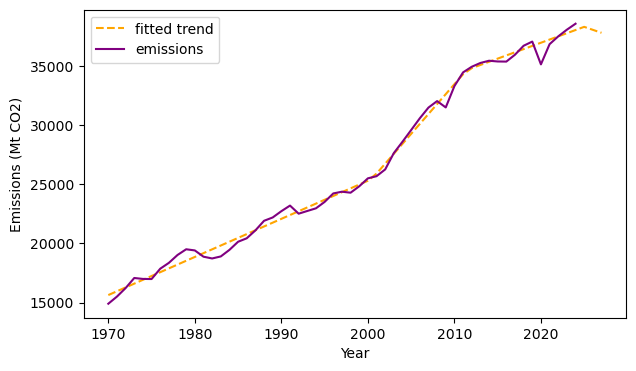

In [7]:
# emissions_tester.residuals.plot()
fig, ax = plt.subplots(figsize=(7,4))
emissions_tester.trend.plot(ax=ax, color = 'orange', linestyle='--', label='fitted trend')
emissions_tester.historical_data.plot(ax=ax, color = 'purple', label='Historical data')
ax.set_xlabel('Year')
ax.set_ylabel(f'Emissions ({emissions_tester.unit})')
ax.legend()
fig.savefig('../outputs/figures/emissions_trend.svg', dpi=300)

In [8]:
def plot_residuals(peak_test, ax=None):
    """
    Plot historical residuals (trend-removed) with innovation residuals overlaid.
    
    emissions_tester.residuals         -> pd.Series with year index (trend residuals)
    emissions_tester.autocorr_params['residuals'] -> np.array (innovation residuals,
                                                      after AR(1) removal, length n-1)
    """
    trend_resid = peak_test.residuals                          # pd.Series, full years
    innov_resid = peak_test.autocorr_params["residuals"]       # np.array, length n-1
    innov_years = trend_resid.index[1:]                        # trim first year to align

    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 4))

    # Trend residuals (bars for easy reading of sign)
    colors = ["#8B7BA8" if v < 0 else "#8B7BA8" for v in trend_resid]
    ax.bar(trend_resid.index, trend_resid.values, color=colors, alpha=0.5,
           width=0.8, label="Trend residuals")

    # Innovation residuals (after AR(1) removal)
    ax.plot(innov_years, innov_resid, color="#333333", linewidth=1.2,
            linestyle="--", marker="o", markersize=3,
            label="Innovation residuals (AR(1) removed)")

    ax.axhline(0, color="black", linewidth=0.8, linestyle="-")

    # Annotate AR(1) params
    phi = peak_test.autocorr_params.get("phi", 0)
    sigma = peak_test.autocorr_params.get("sigma_residuals", None)
    label = f"φ = {phi:.2f}"
    if sigma is not None:
        label += f",  σ = {sigma:.1f} {peak_test.unit}"
    ax.text(0.02, 0.97, label, transform=ax.transAxes,
            va="top", ha="left", fontsize=9, color="#555555")

    ax.set_xlabel("Year")
    ax.set_ylabel(f"Residual ({peak_test.unit})")
    ax.legend(fontsize=9, framealpha=0.5)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3, linewidth=0.5)

    return ax

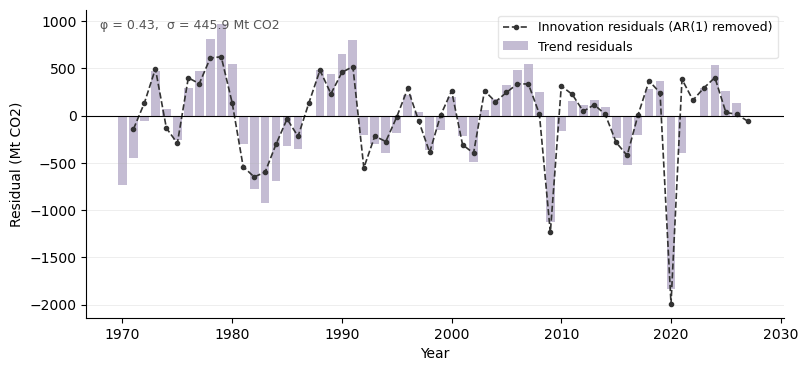

In [9]:
ax = plot_residuals(emissions_tester)
ax.get_figure().savefig('../outputs/figures/residuals_emissions.svg', dpi=300)

In [20]:
emissions_tester.characterize_noise(method='broken_trend',include_test_data=True, forced_breakpoints=[2025], ignore_years=[2020]) # choose 'normal', 't-dist' or 'empirical'. If 't-dist' can choose t_df or leave to calculate
emissions_tester.create_noise_generator()
emissions_tester.run_complete_bootstrap_test(null_hypothesis='zero_trend',bootstrap_method='ar_bootstrap')

Max breakpoints: 12
using t-dist distribution to calculate noise
Fitted t-distribution to innovations: df = 10.4
Autocorrelation analysis:

  Lag-1 autocorr: 0.536
  Residual σ (post-autocorrelation): 363.2
  Has significant autocorr: True
  Likelihood of autocorr: 0.9999674006579559
Noise characterization complete:
  Method used: broken_trend
Using AR(1) noise generator with φ=0.54, mean=0.000, sigma=363.247
Running complete bootstrap test...
  Null hypothesis: zero_trend
  Bootstrap method: ar_bootstrap
  Bootstrap samples: 10000
using slope-based test method
  P-value slope method: 0.0739
  Significant at α=0.1: True
  Effect size: 1.44 standard deviations


In [26]:
def plot_innovation_residuals(peak_test, ax=None):
    """
    Plot innovation residuals as a histogram with a fitted normal distribution overlaid.
    """
    innov_resid = peak_test.autocorr_params["residuals"]
    sigma = peak_test.autocorr_params["sigma_residuals"]
    mean = peak_test.autocorr_params["mean_residuals"]

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))

    # Histogram
    ax.hist(innov_resid, bins=15, density=True,
            color="#8B7BA8", edgecolor="#6B5B8E", linewidth=0.4,
            alpha=0.7, label="Innovation residuals")

    # Normal distribution overlay
    x = np.linspace(innov_resid.min(), innov_resid.max(), 200)
    ax.plot(x, stats.norm.pdf(x, loc=mean, scale=sigma),
            color="#4A3B6E", linewidth=1.8, label=f"N(μ={mean:.1f}, σ={sigma:.1f})")

    ax.set_xlabel(f"Residual ({peak_test.unit})")
    ax.set_ylabel("Density")
    ax.legend(fontsize=9, framealpha=0.5)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3, linewidth=0.5)

    return ax

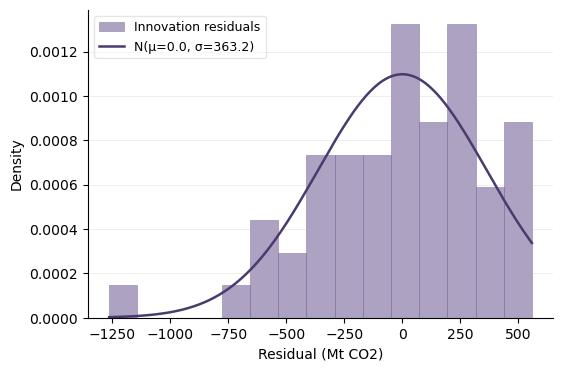

In [28]:
ax = plot_innovation_residuals(emissions_tester)

ax.get_figure().savefig('../outputs/figures/innovation_residuals_distribution.svg', dpi=300)

<Axes: xlabel='Residual (Mt CO2)', ylabel='Density'>

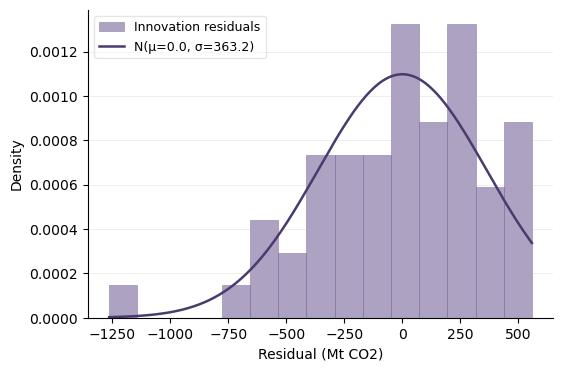

In [27]:
plot_innovation_residuals(emissions_tester)

In [15]:
emissions_tester.characterize_noise(method='broken_trend',include_test_data=True, forced_breakpoints=[2025]) # choose 'normal', 't-dist' or 'empirical'. If 't-dist' can choose t_df or leave to calculate
emissions_tester.create_noise_generator()
emissions_tester.run_complete_bootstrap_test(null_hypothesis='zero_trend',bootstrap_method='ar_bootstrap',test_sequential=True, store_sequential_sims=True)


Max breakpoints: 12
using t-dist distribution to calculate noise
Fitted t-distribution to innovations: df = 3.9
Autocorrelation analysis:

  Lag-1 autocorr: 0.426
  Residual σ (post-autocorrelation): 445.9
  Has significant autocorr: True
  Likelihood of autocorr: 0.999125339994859
Noise characterization complete:
  Method used: broken_trend
Using AR(1) noise generator with φ=0.43, mean=-0.000, sigma=445.914
Running complete bootstrap test...
  Null hypothesis: zero_trend
  Bootstrap method: ar_bootstrap
  Bootstrap samples: 10000
using slope-based test method
Step 1/2: P(simulated ≤ observed) = 0.1912
Step 2/2: P(simulated ≤ observed) = 0.0963
Results:
  P-value sequential method: 0.0184


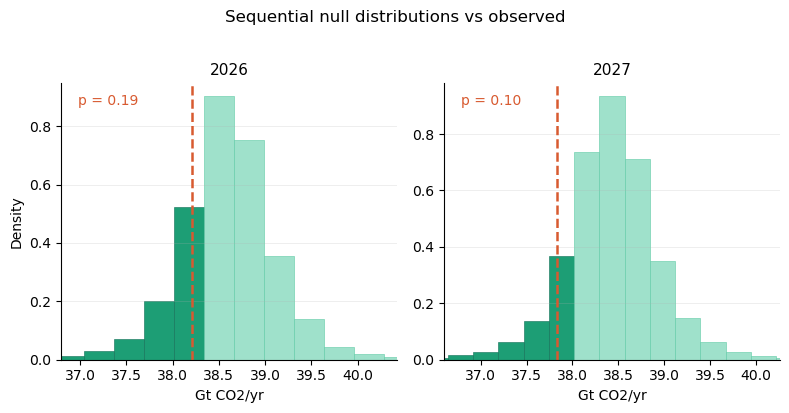

In [30]:
plot_sequential_distributions(emissions_tester)
plt.savefig('../outputs/figures/sequential_distributions_1pct_reduction.svg', dpi=300)

In [45]:
emissions_tester.bootstrap_results['p_sequential_steps']

year
2026    0.1912
2027    0.0963
Name: p_step, dtype: float64

In [25]:
emissions_tester._plot_sequential_sims()

AttributeError: 'EmissionsPeakTest' object has no attribute '_plot_sequential_sims'